# Lab assignment №1, part 3

This lab assignment consists of several parts. You are supposed to make some transformations, train some models, estimate the quality of the models and explain your results.

Several comments:
* Don't hesitate to ask questions, it's a good practice.
* No private/public sharing, please. The copied assignments will be graded with 0 points.
* Blocks of this lab will be graded separately.

__*This is the third part of the assignment. First and second parts are waiting for you in the same directory.*__

##  Part 3. SVM and kernels

Kernels concept get adopted in variety of ML algorithms (e.g. Kernel PCA, Gaussian Processes, kNN, ...).

So in this task you are to examine kernels for SVM algorithm applied to rather simple artificial datasets.

To make it clear: we will work with the classification problem through the whole notebook.

In [1]:
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
import numpy as np

Let's generate our dataset and take a look on it.

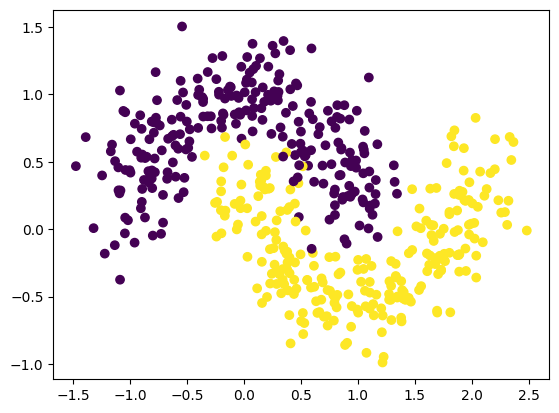

In [2]:
moons_points, moons_labels = make_moons(n_samples=500, noise=0.2, random_state=42)
plt.scatter(moons_points[:, 0], moons_points[:, 1], c=moons_labels)

## 1.1 Pure models.
First let's try to solve this case with good old Logistic Regression and simple (linear kernel) SVM classifier.

Train LR and SVM classifiers (choose params by hand, no CV or intensive grid search neeeded) and plot their decision regions. Calculate one preffered classification metric.

Describe results in one-two sentences.

_Tip:_ to plot classifiers decisions you colud use either sklearn examples ([this](https://scikit-learn.org/stable/auto_examples/neural_networks/plot_mlp_alpha.html#sphx-glr-auto-examples-neural-networks-plot-mlp-alpha-py) or any other) and mess with matplotlib yourself or great [mlxtend](https://github.com/rasbt/mlxtend) package (see their examples for details)

_Pro Tip:_ wirte function `plot_decisions` taking a dataset and an estimator and plotting the results cause you want to use it several times below

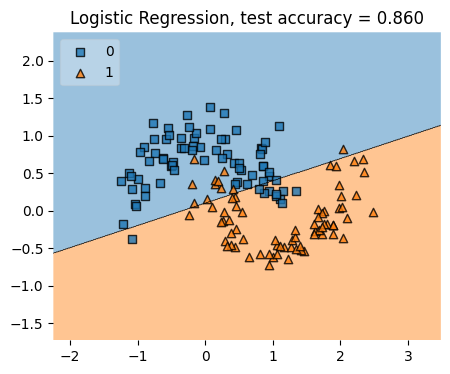

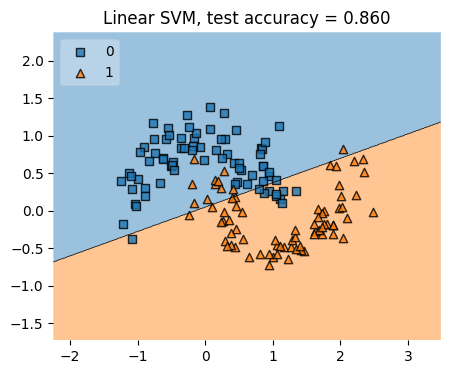

LR accuracy: 0.860, linear SVM accuracy: 0.860


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from mlxtend.plotting import plot_decision_regions

lr = LogisticRegression() # add some params
svm = SVC(kernel='linear') # here too

### YOUR CODE HERE
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(moons_points, moons_labels, test_size=0.3, random_state=42, stratify=moons_labels)

def plot_decisions(X, y, clf, title=''):
    plt.figure(figsize=(5, 4))
    plot_decision_regions(X, y, clf=clf, legend=2)
    plt.title(title)
    plt.show()

def fit_and_plot(clf, name, X_tr, y_tr, X_te, y_te):
    clf.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, clf.predict(X_te))
    plot_decisions(X_te, y_te, clf, f'{name}, test accuracy = {acc:.3f}')

    return acc

acc_lr = fit_and_plot(lr, 'Logistic Regression', X_train, y_train, X_test, y_test)
acc_svm = fit_and_plot(svm, 'Linear SVM', X_train, y_train, X_test, y_test)
print(f'LR accuracy: {acc_lr:.3f}, linear SVM accuracy: {acc_svm:.3f}')

И логистическая регрессия, и линейный SVM дают одинаковые 0.860: обе модели строят прямую границу, а "полумесяцы" линейно неразделимы, поэтому точки вблизи пересечения классов неизбежно классифицируются неверно.

## 1.2 Kernel tirck

Now use different kernels (`poly`, `rbf`, `sigmoid`) on SVC to get better results. Play `degree` parameter and others.

For each kernel estimate optimal params, plot decision regions, calculate metric you've chosen eariler.

Write couple of sentences on:

* What have happenned with classification quality?
* How did decision border changed for each kernel?
* What `degree` have you chosen and why?

poly, degree=2: test accuracy = 0.847
poly, degree=3: test accuracy = 0.987
poly, degree=4: test accuracy = 0.987
poly, degree=5: test accuracy = 0.987


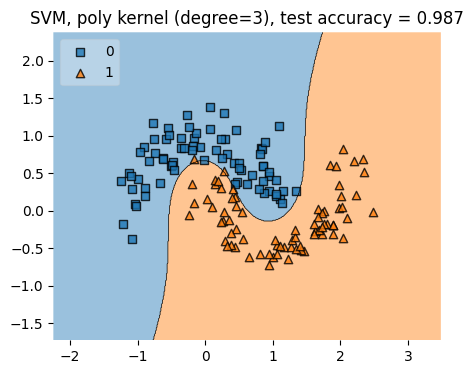

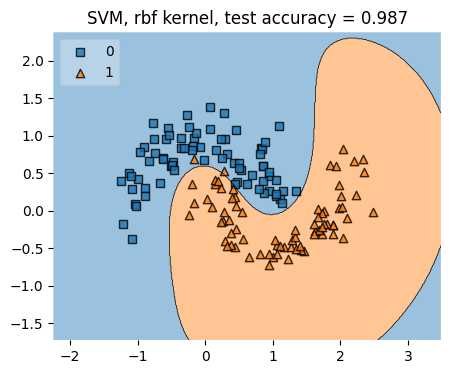

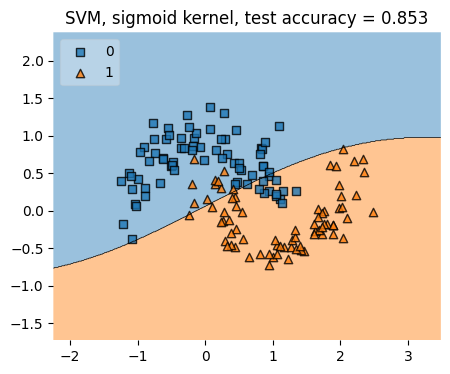

poly: 0.987, rbf: 0.987, sigmoid: 0.853


In [5]:
### YOUR CODE HERE
for d in [2, 3, 4, 5]:
    m = SVC(kernel='poly', degree=d, coef0=1, C=10).fit(X_train, y_train)
    print(f'poly, degree={d}: test accuracy = {accuracy_score(y_test, m.predict(X_test)):.3f}')

svm_poly = SVC(kernel='poly', degree=3, coef0=1, C=10)
svm_rbf = SVC(kernel='rbf', C=1, gamma=1)
svm_sigmoid = SVC(kernel='sigmoid', C=1, gamma=0.1, coef0=0)

acc_poly = fit_and_plot(svm_poly, 'SVM, poly kernel (degree=3)', X_train, y_train, X_test, y_test)
acc_rbf = fit_and_plot(svm_rbf, 'SVM, rbf kernel', X_train, y_train, X_test, y_test)
acc_sigmoid = fit_and_plot(svm_sigmoid, 'SVM, sigmoid kernel', X_train, y_train, X_test, y_test)
print(f'poly: {acc_poly:.3f}, rbf: {acc_rbf:.3f}, sigmoid: {acc_sigmoid:.3f}')

* **Качество.** `poly` и `rbf` повысили accuracy с 0.860 (линейные модели) до 0.987, т.е. почти убрали ошибки. `sigmoid` улучшения не дал (0.853, на уровне линейных моделей): при увеличении `gamma` качество у него только падало, т.к. это ядро не гарантирует положительную определённость и плохо подходит для данной задачи.
* **Граница.** `poly` - гладкая кривая (полином 3-й степени), уходящая в бесконечность по краям; `rbf` - гладкая локальная граница, которая отличается незначительным кол-ом точек от предыдущей; `sigmoid` - почти прямая с небольшим изгибом (выглядит как собственно и график сигмоиды).
* **Degree.** Выбрано `degree=3`: при `degree=2` accuracy всего 0.847, при 3 она сразу достигает 0.987, а степени 4 и 5 ничего не добавляют только усложняя модель и повышая риск переобучения, поэтому берем минимальную достаточную степень.

## 1.3 Simpler solution (of a kind)
What is we could use Logisitc Regression to successfully solve this task?

Feature generation is a thing to help here. Different techniques of feature generation are used in real life, couple of them will be covered in additional lectures.

In particular case simple `PolynomialFeatures` ([link](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)) are able to save the day.

Generate the set of new features, train LR on it, plot decision regions, calculate metric.

* Comare SVM's results with this solution (quality, borders type)
* What degree of PolynomialFeatures have you used? Compare with same SVM kernel parameter.

LR + PolynomialFeatures(degree=2): test accuracy = 0.847
LR + PolynomialFeatures(degree=3): test accuracy = 0.987
LR + PolynomialFeatures(degree=4): test accuracy = 0.980
LR + PolynomialFeatures(degree=5): test accuracy = 0.987


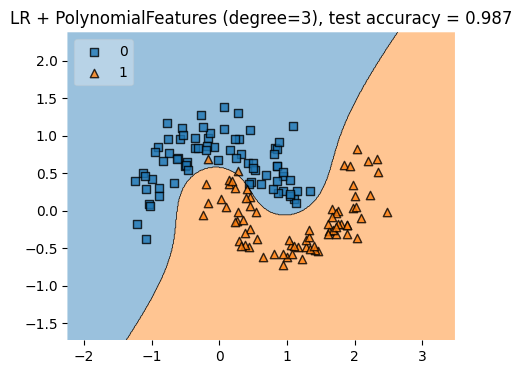

LR + poly features: 0.987 (poly SVM: 0.987, rbf SVM: 0.987)


In [6]:
from sklearn.preprocessing import PolynomialFeatures

### YOUR CODE HERE
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Подбор степени полиномиальных признаков
for d in [2, 3, 4, 5]:
    m = make_pipeline(PolynomialFeatures(d), StandardScaler(), LogisticRegression(C=10, max_iter=1000))
    m.fit(X_train, y_train)
    print(f'LR + PolynomialFeatures(degree={d}): test accuracy = {accuracy_score(y_test, m.predict(X_test)):.3f}')

lr_poly = make_pipeline(PolynomialFeatures(3), StandardScaler(), LogisticRegression(C=10, max_iter=1000))
acc_lr_poly = fit_and_plot(lr_poly, 'LR + PolynomialFeatures (degree=3)', X_train, y_train, X_test, y_test)
print(f'LR + poly features: {acc_lr_poly:.3f} (poly SVM: {acc_poly:.3f}, rbf SVM: {acc_rbf:.3f})')

LR на полиномиальных признаках степени 3 accuracy 0.987 - ровно столько же, сколько SVM с poly-ядром и rbf-ядром;

Граница при этом почти совпадает с границей poly-SVM (гладкая S-образная кривая), т.е. по качеству и типу границы решения почти эквивалентны.

Использована степень 3 - та же, что и в poly-ядре SVM, и в обоих случаях степень 2 не справляется (0.847), а начиная с 3 качество выходит на плато.

Разница в способе: `PolynomialFeatures` создаёт новые признаки (для 2 исходных признаков и степени 3 - всего 10), а ядро считает скалярные произведения в этом пространстве неявно, поэтому при большом числе признаков или высоких степенях ядра заметно дешевле, а rbf-ядро вообще соответствует бесконечномерному пространству признаков, которое явно не построить.

## 1.4 Harder problem

Let's make this task a bit more challenging via upgrading dataset:

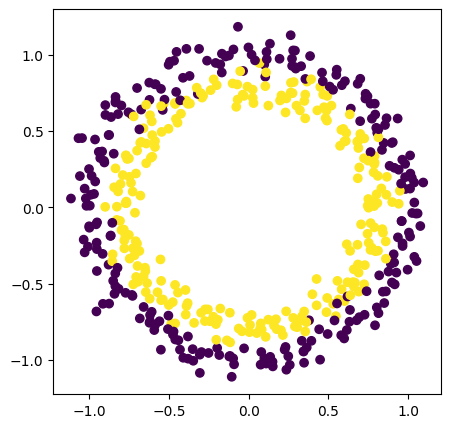

In [7]:
from sklearn.datasets import make_circles

circles_points, circles_labels = make_circles(n_samples=500, noise=0.06, random_state=42)

plt.figure(figsize=(5, 5))
plt.scatter(circles_points[:, 0], circles_points[:, 1], c=circles_labels)

And even more:

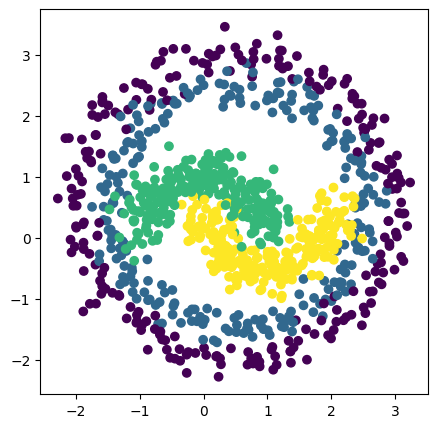

In [8]:
points = np.vstack((circles_points*2.5 + 0.5, moons_points))
labels = np.hstack((circles_labels, moons_labels + 2)) # + 2 to distinct moons classes

plt.figure(figsize=(5, 5))
plt.scatter(points[:, 0], points[:, 1], c=labels)

Now do your best using all the approaches above!

Tune LR with generated features, SVM with appropriate kernel of your choice. You may add some of your loved models to demonstrate their (and your) strength. Again plot decision regions, calculate metric.

Justify the results in a few phrases.

/usr/local/lib/python3.13/dist-packages/mlxtend/plotting/decision_regions.py:346: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(


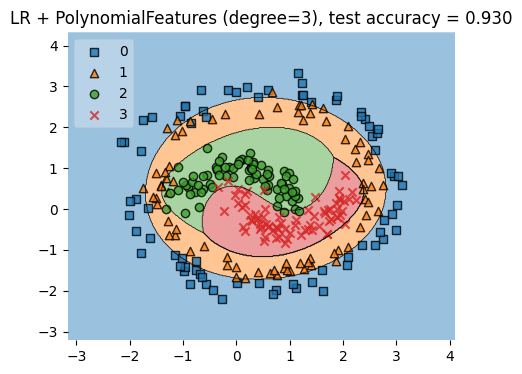

/usr/local/lib/python3.13/dist-packages/mlxtend/plotting/decision_regions.py:346: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(


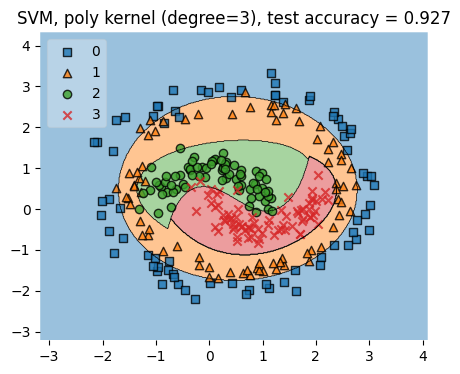

/usr/local/lib/python3.13/dist-packages/mlxtend/plotting/decision_regions.py:346: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(


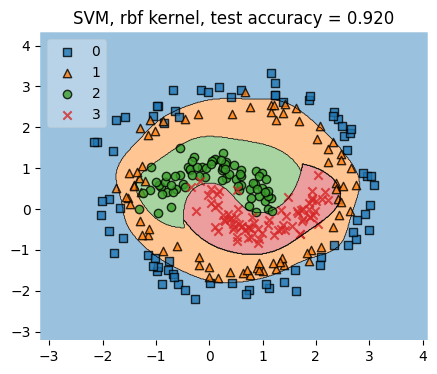

/usr/local/lib/python3.13/dist-packages/mlxtend/plotting/decision_regions.py:346: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(


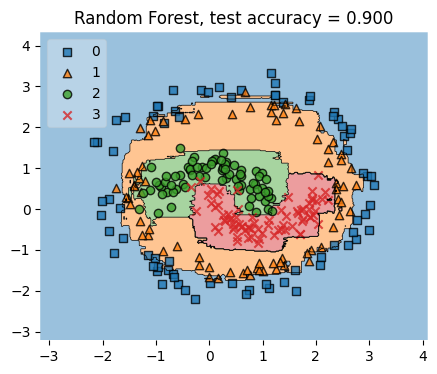

LR + PolynomialFeatures (degree=3): 0.930
SVM, poly kernel (degree=3): 0.927
SVM, rbf kernel: 0.920
Random Forest: 0.900
Linear SVM (baseline): 0.443


In [9]:
### YOUR CODE HERE
from sklearn.ensemble import RandomForestClassifier

Xh_train, Xh_test, yh_train, yh_test = train_test_split(points, labels, test_size=0.3, random_state=42, stratify=labels)
models = {
    'LR + PolynomialFeatures (degree=3)': make_pipeline(
        PolynomialFeatures(3), StandardScaler(), LogisticRegression(C=100, max_iter=5000)),
    'SVM, poly kernel (degree=3)': SVC(kernel='poly', degree=3, coef0=1, C=10),
    'SVM, rbf kernel': SVC(kernel='rbf', C=10, gamma=1),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=42),
}
results = {}

for name, model in models.items():
    results[name] = fit_and_plot(model, name, Xh_train, yh_train, Xh_test, yh_test)

results['Linear SVM (baseline)'] = accuracy_score(
    yh_test, SVC(kernel='linear').fit(Xh_train, yh_train).predict(Xh_test))

for name, a in results.items():
    print(f'{name}: {a:.3f}')

Линейная модель на этих данных бесполезна (accuracy 0.443), а все нелинейные подходы дают 0.90-0.93:

LR на полиномиальных признаках степени 3 - 0.930;

SVM с poly-ядром (degree=3) - 0.927;

SVM с rbf-ядром - 0.920;

Random Forest - 0.900.

Разница между первыми тремя - 1-2 объекта из 300 тестовых (один объект = 0.33%), то есть они стат. неразличимы; лучшей оказалась LR + PolynomialFeatures, но выбирать между ними нужно по простоте и скорости.

Потолок качества ограничен самими данными: классы 2 и 3 шумные и перекрываются друг с другом, а также частично заходят на кольцо класса 1, поэтому безошибочно разделить классы нельзя ни одной моделью.

Гладкие границы (эллипс для колец и кривая для "лун") хорошо описываются полиномами степени 3 и rbf-ядром, а Random Forest строит кусочно-постоянные "прямоугольные" области и хуже обобщает на шумных точках.